   AnnualIncome_k  SpendingScore
0            86.1           87.2
1            89.2           69.9
2            73.3           75.2
3           115.6           57.3
4            61.5           87.3


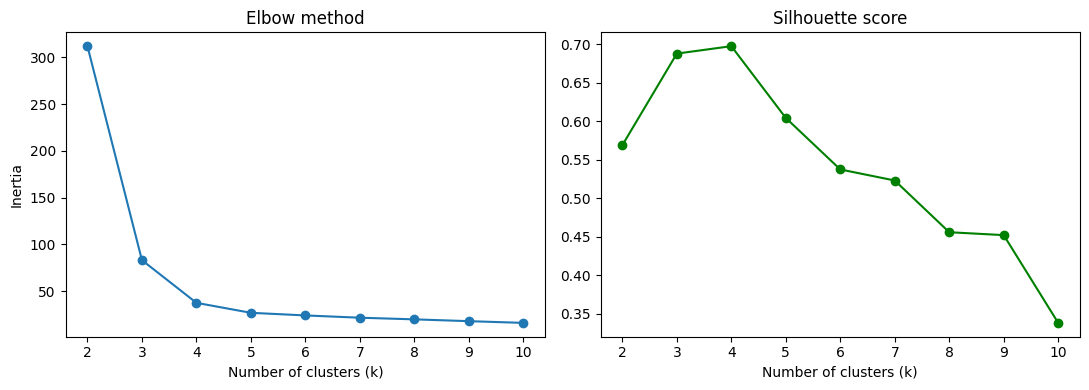

Best k by silhouette score: 4


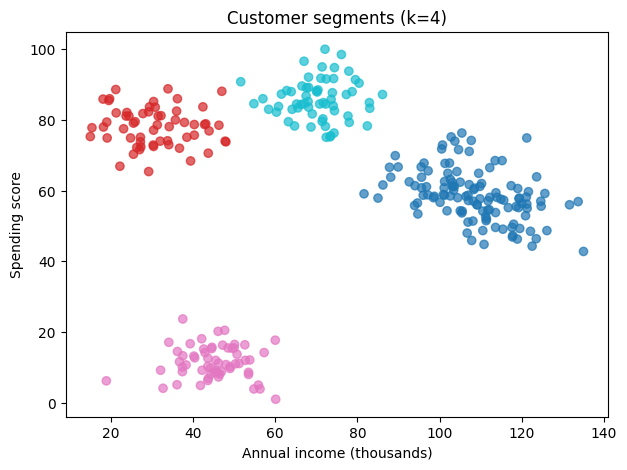

         Customers  Avg_Income  Avg_Spending
Segment                                     
0              120       108.5          58.7
1               59        30.8          78.1
2               60        45.2          11.4
3               61        70.4          85.7


In [1]:
# Customer Segmentation using K-Means Clustering
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 1. Create sample customer data (synthetic, 300 customers)
X, _ = make_blobs(n_samples=300, centers=5, cluster_std=1.2, random_state=42)

def rescale(col, low, high):
    return (col - col.min()) / (col.max() - col.min()) * (high - low) + low

df = pd.DataFrame({
    "AnnualIncome_k": rescale(X[:, 0], 15, 135).round(1),   # income in thousands
    "SpendingScore": rescale(X[:, 1], 1, 100).round(1)      # score from 1 to 100
})
print(df.head())

# 2. Scale the data so both columns count equally
scaled = StandardScaler().fit_transform(df)

# 3. Find the best number of groups (k)
inertias, scores = [], []
k_values = range(2, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(scaled)
    inertias.append(model.inertia_)
    scores.append(silhouette_score(scaled, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, scores, marker="o", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

best_k = list(k_values)[scores.index(max(scores))]
print("Best k by silhouette score:", best_k)

# 4. Train the final model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["Segment"] = kmeans.fit_predict(scaled)

# 5. Plot the segments
plt.figure(figsize=(7, 5))
plt.scatter(df["AnnualIncome_k"], df["SpendingScore"], c=df["Segment"], cmap="tab10", alpha=0.7)
plt.xlabel("Annual income (thousands)")
plt.ylabel("Spending score")
plt.title(f"Customer segments (k={best_k})")
plt.show()

# 6. Describe each segment
print(df.groupby("Segment").agg(
    Customers=("Segment", "count"),
    Avg_Income=("AnnualIncome_k", "mean"),
    Avg_Spending=("SpendingScore", "mean")
).round(1))